## 1. Setup
### 1a. Import Libraries

In [1]:
# ==========================================
# Requirements & Environment Documentation
# ==========================================
# System Requirements:
# - Python 3.8+
# - MATLAB R2022a or newer 
# - MATLAB Toolboxes: 
#   * Statistics and Machine Learning Toolbox (for fitrgp)
#   * Predictive Maintenance Toolbox (for phaseSpaceReconstruction)
# 
# Python Package Dependencies:
# - matlabengine
# - numpy, pandas, scipy, scikit-learn
# - matplotlib, seaborn
# - pyEDM (Pinned version recommended for SMap compatibility)
# - joblib, tqdm, ipython
# ==========================================

import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import scipy
import sklearn
import joblib
import pyEDM

print("Python version:", sys.version.split('|')[0].strip())
print(f"{'numpy:':<15} {np.__version__}")
print(f"{'pandas:':<15} {pd.__version__}")
print(f"{'matplotlib:':<15} {matplotlib.__version__}")
print(f"{'seaborn:':<15} {sns.__version__}")
print(f"{'scipy:':<15} {scipy.__version__}")
print(f"{'sklearn:':<15} {sklearn.__version__}")
print(f"{'joblib:':<15} {joblib.__version__}")
print(f"{'pyEDM:':<15} {pyEDM.__version__}")

# Set random seeds for total reproducibility
import random
seed = 42
random.seed(seed)
np.random.seed(seed)


Python version: 3.12.2
numpy:          2.4.6
pandas:         3.0.3
matplotlib:     3.11.0
seaborn:        0.13.2
scipy:          1.18.0
sklearn:        1.9.0
joblib:         1.5.3
pyEDM:          2.5.7


In [2]:
import os
import atexit
from pathlib import Path
import matlab.engine
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from matplotlib.patches import ConnectionPatch
from mpl_toolkits.mplot3d import proj3d
from sklearn.neighbors import NearestNeighbors 

DATA_DIR = Path("Data").resolve()
FIG_DIR = Path("Figures").resolve()
RESULTS_DIR = Path("Results").resolve()
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [5]:
# Set up matlabengine for running MATLAB code

MATLAB_DIR = Path('matlab_workspace').resolve()
MATLAB_DIR.mkdir(exist_ok=True)

_ENG = None

def get_matlab_engine():
    global _ENG
    if _ENG is not None:
        return _ENG
    
    # Start engine
    eng = matlab.engine.start_matlab()
    eng.addpath(str(MATLAB_DIR), nargout=0)
    _ENG = eng
    return _ENG

def reset_matlab_engine():
    global _ENG
    if _ENG is not None:
        try:
            # Safely quit the engine
            _ENG.quit()
        except Exception:
            pass
        finally:
            _ENG = None

# Register cleanup on Python exit
atexit.register(reset_matlab_engine)

# Helper to write M-files to the workspace directory
def add_matlab_function(func_name: str, code: str):
    """Saves a MATLAB function/script string into the workspace directory."""
    file_path = MATLAB_DIR / f"{func_name}.m"
    file_path.write_text(code.strip())
    # Force MATLAB to re-hash the path to recognize newly created or updated files immediately
    eng = get_matlab_engine()
    eng.rehash(nargout=0)

# Helper to execute arbitrary inline MATLAB code blocks
def run_matlab(code: str, **workspace_inputs):
    """
    Executes raw MATLAB code.
    Optionally pass python variables as key=value arguments to load into MATLAB's workspace.
    """
    eng = get_matlab_engine()
    # Inject inputs into MATLAB workspace
    for key, val in workspace_inputs.items():
        if isinstance(val, (np.ndarray, list)):
            val = matlab.double(np.asarray(val).tolist())
        eng.workspace[key] = val
        
    eng.eval(code, nargout=0)

# Initialize engine immediately on startup
eng = get_matlab_engine()


### 1b. Generate Synthetic Datasets

In [6]:
generate_synthetic_data = True

In [7]:
# Lorenz 120D system
if generate_synthetic_data:
    add_matlab_function('multiCoupledLorenz', """
        function dXdt = multiCoupledLorenz(t, X, sigma, rho, beta, epsilon, N)
        % multiCoupledLorenz: Compute the derivatives for a network of coupled Lorenz systems
    
        % Initialize the derivative vector
        dXdt = zeros(3*N, 1);
        
        % Iterate over each Lorenz subsystem to compute derivatives
        for i = 1:N
            % Extract state variables for the i-th subsystem
            x_i = X(3*(i-1)+1);
            y_i = X(3*(i-1)+2);
            z_i = X(3*(i-1)+3);
            
            % Standard Lorenz equations (without coupling)
            dx = sigma * (y_i - x_i);
            dy = x_i * (rho - z_i) - y_i;
            dz = x_i * y_i - beta * z_i;
            
            % Add linear coupling term in the x-direction (diffusive coupling)
            if N > 1
                coupling_x = 0;
                for j = 1:N
                    if j ~= i
                        x_j = X(3*(j-1)+1);
                        coupling_x = coupling_x + (x_j - x_i);
                    end
                end
                dx = dx + epsilon * coupling_x;
            end
            
            % Assign computed derivatives to the output vector
            dXdt(3*(i-1)+1) = dx;
            dXdt(3*(i-1)+2) = dy;
            dXdt(3*(i-1)+3) = dz;
        end
    end
    """)

    # MATLAB code to generate Lorenz data (authors' code)
    lorenz_script = """
    sigma = 10;
    rho = 28;
    beta = 8/3;
    epsilon = 0.1; % coupling strength
    N = 40; % number of coupled subsystems
    
    % Initial conditions
    x(:,1)=0.3:0.3:(0.3+0.3*(3*N-1));
    X0=x;
     
    % Time span for simulation
    tspan = [10 40];
    
    % Solve the system of differential equations
    [t, X] = ode45(@(t, X) multiCoupledLorenz(t, X, sigma, rho, beta, epsilon, N), tspan, X0);
    t=t(101:end,:);
    X=X(101:end,:);
    y=X+0*randn(length(X),1); % additive noise
    """
    
    run_matlab(lorenz_script)
    
    # Pull results directly out of MATLAB's global workspace into Python/NumPy
    t_py = np.array(eng.workspace['t']).ravel()
    X_py = np.array(eng.workspace['X'])
    y_py = np.array(eng.workspace['y'])
    
    # Create DataFrame (naming columns x1, y1, z1, ..., x40, y40, z40)
    N = 40
    var_names = ['X', 'Y', 'Z']
    cols = [f"{var_names[i % 3]}{(i // 3) + 1}" for i in range(3 * N)]
    
    df_lorenz = pd.DataFrame(y_py, columns=cols)
    
    csv_path = DATA_DIR / "lorenz120D_w0.1.csv"
    df_lorenz.to_csv(csv_path, index=False)
    
    print(f"Saved DataFrame of shape {df_lorenz.shape} to:\n{csv_path}")


Saved DataFrame of shape (1829, 120) to:
/Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/lorenz120D_w0.1.csv


In [8]:
# Rossler 120D System
if generate_synthetic_data:
    add_matlab_function('multiCoupledRossler', """
        function dXdt = multiCoupledRossler(t, X, a, b, c, epsilon, N)
        % multiCoupledRossler: Compute the derivatives for a network of coupled Rossler systems

        % Initialize the derivative vector
        dXdt = zeros(3*N, 1);

        % Iterate over each Rossler subsystem to compute derivatives
        for i = 1:N
            % Extract state variables for the i-th subsystem
            x_i = X(3*(i-1)+1);
            y_i = X(3*(i-1)+2);
            z_i = X(3*(i-1)+3);
            
            % Standard Rossler system equations
            dx = -y_i - z_i;
            dy = x_i + a * y_i;
            dz = b + z_i * (x_i - c);
            
            % Add linear coupling term in the x-direction (diffusive coupling)
            if N > 1
                coupling_x = 0;
                for j = 1:N
                    if j ~= i
                        x_j = X(3*(j-1)+1);
                        coupling_x = coupling_x + (x_j - x_i);
                    end
                end
                dx = dx + epsilon * coupling_x;
            end

            % Assign computed derivatives to the output vector
            dXdt(3*(i-1)+1) = dx;
            dXdt(3*(i-1)+2) = dy;
            dXdt(3*(i-1)+3) = dz;
        end
    end
    """)

    rossler_script = """
    a = 0.2;
    b = 0.2;
    c = 5.7;
    epsilon = 0.01; % coupling strength (w = 0.01)
    N = 40; % number of coupled subsystems (3N = 120 dimensions)

    % Initial conditions
    X0 = (0.1 : 0.03 : (0.1 + 0.03 * (3*N - 1)))'; 
     
    % Time span: [0 100] with exactly 1717 points generated
    tspan = linspace(0, 100, 1717);

    % Solve differential equations using ode45 at exact points specified in tspan
    [t, X] = ode45(@(t, X) multiCoupledRossler(t, X, a, b, c, epsilon, N), tspan, X0);
    
    % Remove first 100 data points to eliminate transient states (yields 1617 points)
    X = X(101:end, :);
    t = t(101:end);
    y = X + 0 * randn(length(X), 1); % additive noise matching authors' code layout
    """

    run_matlab(rossler_script)
    
    # Pull results directly out of MATLAB's global workspace into Python/NumPy
    t_py = np.array(eng.workspace['t']).ravel()
    X_py = np.array(eng.workspace['X'])
    y_py = np.array(eng.workspace['y'])
    
    # Create DataFrame (naming columns X1, Y1, Z1, ..., X40, Y40, Z40)
    N = 40
    var_names = ['X', 'Y', 'Z']
    cols = [f"{var_names[i % 3]}{(i // 3) + 1}" for i in range(3 * N)]
    
    df_rossler = pd.DataFrame(y_py, columns=cols)
    
    csv_path = DATA_DIR / "rossler120D_w0.01.csv"
    df_rossler.to_csv(csv_path, index=False)
    
    print(f"Saved DataFrame of shape {df_rossler.shape} to:\n{csv_path}")


Saved DataFrame of shape (1617, 120) to:
/Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/rossler120D_w0.01.csv


In [9]:
# 3D ecology system
if generate_synthetic_data:
    ecology_script = """
    % Generate 3-variable ecological time series
    % Note: 'clear' removed to preserve engine context
    y1 = zeros(601, 1);
    y2 = zeros(601, 1);
    y3 = zeros(601, 1);

    y1(1) = 0.4;
    y2(1) = 0.5;
    y3(1) = 0.6;
    
    % Iterative time series generation
    for t = 1:600
        y1(t+1) = y1(t)*(4 - 4*y1(t) - 2*y2(t) - 0.4*y3(t));
        y2(t+1) = y2(t)*(3.1 - 0.31*y1(t) - 3.1*y2(t) - 0.93*y3(t));
        y3(t+1) = y3(t)*(2.12 + 0.636*y1(t) + 0.636*y2(t) - 2.12*y3(t));
    end
    
    % Combine series into matrix 'x'
    x = [y1, y2, y3];
    
    % Remove transient points (first 100 iterations)
    x = x(101:end, :);
    """
    
    run_matlab(ecology_script)

    x_py = np.array(eng.workspace['x'])
    
    cols = [f"X{i+1}" for i in range(x_py.shape[1])]
    df_ecology = pd.DataFrame(x_py, columns=cols)
    
    csv_path = DATA_DIR / "ecology3D.csv"
    df_ecology.to_csv(csv_path, index=False)
    
    print(f"Saved DataFrame of shape {df_ecology.shape} to:\n{csv_path}")


Saved DataFrame of shape (501, 3) to:
/Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/ecology3D.csv


In [10]:
# Full 5D ecology system
if generate_synthetic_data:
    ecology_script = """
    % Generate 5-variable ecological time series (Sugihara et al. 2012, Eq. S5)
    T = 600;
    
    y1 = zeros(T + 1, 1);
    y2 = zeros(T + 1, 1);
    y3 = zeros(T + 1, 1);
    y4 = zeros(T + 1, 1);
    y5 = zeros(T + 1, 1);

    % Initial conditions
    y1(1) = 0.4;
    y2(1) = 0.5;
    y3(1) = 0.6;
    y4(1) = 0.2;
    y5(1) = 0.3;
    
    % Iterative time series generation
    for t = 1:T
        y1(t+1) = y1(t)*(4 - 4*y1(t) - 2*y2(t) - 0.4*y3(t));
        y2(t+1) = y2(t)*(3.1 - 0.31*y1(t) - 3.1*y2(t) - 0.93*y3(t));
        y3(t+1) = y3(t)*(2.12 + 0.636*y1(t) + 0.636*y2(t) - 2.12*y3(t));
        y4(t+1) = y4(t)*(3.8 - 0.111*y1(t) - 0.011*y2(t) + 0.131*y3(t) - 3.8*y4(t));
        y5(t+1) = y5(t)*(4.1 - 0.082*y1(t) - 0.111*y2(t) - 0.125*y3(t) - 4.1*y5(t));
    end
    
    % Combine series into matrix 'x'
    x = [y1, y2, y3, y4, y5];
    
    % Remove first 100 transient data points
    x = x(101:end, :);
    """
    
    run_matlab(ecology_script)

    x_py = np.array(eng.workspace['x'])
    
    cols = [f"X{i+1}" for i in range(x_py.shape[1])]
    df_ecology = pd.DataFrame(x_py, columns=cols)
    
    csv_path = DATA_DIR / "ecology5D.csv"
    df_ecology.to_csv(csv_path, index=False)
    
    print(f"Saved DataFrame of shape {df_ecology.shape} to:\n{csv_path}")


Saved DataFrame of shape (501, 5) to:
/Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/ecology5D.csv


In [11]:
# Lorenz 3D system
if generate_synthetic_data:
    # MATLAB code to generate Lorenz data (authors' code)
    lorenz_script = """
    sigma = 10;
    rho = 28;
    beta = 8/3;
    epsilon = 0.1; % coupling strength
    N = 1; % number of coupled subsystems
    
    % Fixed Initial conditions
    X0 = (0.3:0.3:0.9)';
     
    % Time span for simulation
    tspan = [10 40];
    
    % Solve the system of differential equations
    [t, X] = ode45(@(t, X) multiCoupledLorenz(t, X, sigma, rho, beta, epsilon, N), tspan, X0);
    X = X(101:end,:);
    y = X + 0*randn(length(X),1); % additive noise
    """
    
    run_matlab(lorenz_script)
    
    t_py = np.array(eng.workspace['t']).ravel()
    X_py = np.array(eng.workspace['X'])
    y_py = np.array(eng.workspace['y'])
    
    N = 1
    var_names = ['X', 'Y', 'Z']
    cols = [f"{var_names[i % 3]}{(i // 3) + 1}" for i in range(3 * N)]
    
    df_lorenz = pd.DataFrame(y_py, columns=cols)
    
    csv_path = DATA_DIR / "lorenz3D.csv"
    df_lorenz.to_csv(csv_path, index=False)
    
    print(f"Saved DataFrame of shape {df_lorenz.shape} to:\n{csv_path}")


Saved DataFrame of shape (1453, 3) to:
/Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/lorenz3D.csv


In [12]:
# Driven Lorenz 5D system (2D Harmonic Driver -> 3D Driven Lorenz)
if generate_synthetic_data:
    target_csv = str(DATA_DIR / "driven_lorenz_dataset.csv")

    driven_lorenz_script = f"""
    clear; clc;
    % System Parameters
    sigma = 10; rho_0 = 28; beta = 8/3;
    omega = 0.2; A_rho = 10;
    W0 = [1; 0; 0.3; 0.3; 0.3];
    tspan = [0 500];

    % Inline ODE definition
    drivenODE = @(t, W) [ ...
        omega * W(2); ...                                       % du (Driver 1)
       -omega * W(1); ...                                       % dv (Driver 2)
        sigma * (W(4) - W(3)); ...                              % dx (Driven Lorenz x)
        W(3) * ((rho_0 + A_rho * W(1)) - W(5)) - W(4); ...      % dy (Driven Lorenz y)
        W(3) * W(4) - beta * W(5) ...                           % dz (Driven Lorenz z)
    ];

    % Integrate ODE
    options = odeset('RelTol', 1e-8, 'AbsTol', 1e-10);
    [t, W] = ode45(drivenODE, tspan, W0, options);

    % Discard transient trajectory (t < 20)
    valid_idx = t >= 20;
    t = t(valid_idx);
    W = W(valid_idx, :);

    % Create Data Table
    T = table(t, W(:,1), W(:,2), W(:,3), W(:,4), W(:,5), ...
        'VariableNames', {{'time', 'u_driver', 'v_driver', 'x_lorenz', 'y_lorenz', 'z_lorenz'}});

    % Export to CSV
    writetable(T, '{target_csv}');
    disp(['Successfully exported time series to ', '{target_csv}']);
    """
    
    # Save the ODE function as well, in case other parts of MATLAB need it
    add_matlab_function('drivenLorenzODE', """
function dWdt = drivenLorenzODE(~, W, sigma, rho_0, beta, omega, A_rho)
u = W(1); v = W(2);
x = W(3); y = W(4); z = W(5);
du =  omega * v;
dv = -omega * u;
rho_t = rho_0 + A_rho * u;
dx = sigma * (y - x);
dy = x * (rho_t - z) - y;
dz = x * y - beta * z;
dWdt = [du; dv; dx; dy; dz];
end
    """)

    run_matlab(driven_lorenz_script)


Successfully exported time series to /Users/deliacarpenter/Desktop/DRAFT14.2 Code/Data/driven_lorenz_dataset.csv


### 1c. Load Datasets

In [16]:
# Synthetic datasets
try:
    ecology3D_df     = pd.read_csv(DATA_DIR / 'ecology3D.csv')
    ecology5D_df     = pd.read_csv(DATA_DIR / 'ecology5D.csv')
    lorenz3D_df      = pd.read_csv(DATA_DIR / 'lorenz3D.csv')
    lorenz120D_df    = pd.read_csv(DATA_DIR / 'lorenz120D_w0.1.csv')
    rossler120D_df   = pd.read_csv(DATA_DIR / 'rossler120D_w0.01.csv')

    # Real-world datasets
    road_df          = pd.read_excel(DATA_DIR / 'Transportation.xlsx', header=None).pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    eeg_df           = pd.read_excel(DATA_DIR / 'EEG data.xlsx', header=None)[1:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    exchange_df      = pd.read_excel(DATA_DIR / 'Exchange rates.xlsx', header=None)[2:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    wind_df          = pd.read_csv(DATA_DIR / 'Wind speed.csv').pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))

    # Preprocessing
    eeg_df = (eeg_df - eeg_df.mean()) / eeg_df.std()
    exchange_df = (exchange_df - exchange_df.mean()) / exchange_df.std()
    exchange_df = exchange_df.reset_index(drop=True)
    exchange_df = exchange_df.astype(float)

    # S-map / MVCM settings
    DEFAULTS = dict(E_list=[1,5,9], tau_list=[-1,-5,-9], theta_list=[1.,5.,9.])

    SYSTEMS = {
        'ecology3D':    dict(df=ecology3D_df,   full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
        'lorenz3D':     dict(df=lorenz3D_df,    full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
        'lorenz120D':   dict(df=lorenz120D_df,  full='X1', E_reported=4, tau_reported=3, **DEFAULTS),
        'rossler120D':  dict(df=rossler120D_df, full='X1', E_reported=5, tau_reported=2, **DEFAULTS),
        'road':         dict(df=road_df,        full='X1', E_reported=6, tau_reported=4, **DEFAULTS),
        'eeg':          dict(df=eeg_df,         full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
        'exchange':     dict(df=exchange_df,    full='X1', E_reported=4, tau_reported=4, **DEFAULTS),
        'wind':         dict(df=wind_df,        full='X1', E_reported=4, tau_reported=6, **DEFAULTS),
    }
except Exception as e:
    print(f"Files not found yet. Generate data first. {e}")


## 2. Plotting
### 2a. Visualize Time Series and Cross-Correlation

In [17]:
make_plots = True

# Plot time series data and cross-correlation matrices for each system
if make_plots:
    # Configurations for 3D grouped systems (Filtered for full sweep)
    systems_3d = [
        {"df": lorenz120D_df,  "system_name": "Lorenz",  "coupling_strength": 0.1},
        {"df": rossler120D_df, "system_name": "Rossler", "coupling_strength": 0.01},
    ]
    
    # Configurations for 1D grouped systems (Filtered for full sweep)
    systems_1d = [
        {"df": road_df,     "system_name": "Road"},
        {"df": eeg_df,      "system_name": "EEG"},
        {"df": exchange_df, "system_name": "Exchange"},
        {"df": wind_df,     "system_name": "Wind"},
    ]
    
    # 1. Loop through 3D Systems
    for system_config in tqdm(systems_3d, 'Making figures for 3d systems'):
        plot_df = system_config["df"]
        system_name = system_config["system_name"]
        coupling_strength = system_config["coupling_strength"]
        n_dim = len(plot_df.columns)
    
        w_suffix = f"_w{coupling_strength}" if coupling_strength is not None else ""
        title_coupling = rf" ($\omega$={coupling_strength})" if coupling_strength is not None else ""
    
        # Time series trajectories
        fig, ax = plt.subplots(3, 1, figsize=(7, 5), sharex=True, dpi=300)
        names = ['X', 'Y', 'Z']
        panel_labels = ['(a)', '(b)', '(c)']
        for axi, name in enumerate(names):
            x_cols = [col for col in plot_df.columns if col.startswith(name)]
            for col in x_cols:
                ax[axi].plot(plot_df.index, plot_df[col], linewidth=0.5, alpha=0.5)
            ax[axi].set_ylabel(f"{name} Components")
            ax[axi].text(0.01, 1.0, panel_labels[axi], transform=ax[axi].transAxes, va='top')
            ax[axi].spines['top'].set_visible(False)
            ax[axi].spines['right'].set_visible(False)
            ax[axi].grid(True, linestyle=':', alpha=0.4, color='gray')
    
        ax[-1].set_xlabel("Time Step (t)")
        ax[0].set_title(f"{n_dim}-Dimensional {system_name} System Trajectories{title_coupling}", y=0.98, pad=15)
        fig.align_ylabels(ax)
        fig.tight_layout()
    
        plt.savefig(FIG_DIR / f"{system_name}_{n_dim}d_trajectories{w_suffix}.png", bbox_inches='tight', dpi=300)
        plt.close(fig)
    
        # Correlation matrix heatmap
        x_cols = sorted([col for col in plot_df.columns if col.startswith('X')])
        y_cols = sorted([col for col in plot_df.columns if col.startswith('Y')])
        z_cols = sorted([col for col in plot_df.columns if col.startswith('Z')])
        ordered_cols = x_cols + y_cols + z_cols
    
        corr_matrix = plot_df[ordered_cols].corr()
        num_x, num_y, num_z = len(x_cols), len(y_cols), len(z_cols)
        boundaries = [num_x, num_x + num_y]
    
        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        sns.heatmap(
            corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0, center=0, square=True,
            cbar_kws={"label": "Pearson Correlation Coefficient ($r$)", "shrink": 0.82, "ticks": [-1.0, -0.5, 0.0, 0.5, 1.0]},
            xticklabels=False, yticklabels=False, ax=ax
        )
    
        for b in boundaries:
            ax.axhline(b, color="white", linewidth=1.5)
            ax.axvline(b, color="white", linewidth=1.5)
    
        block_centers = [num_x / 2, num_x + (num_y / 2), num_x + num_y + (num_z / 2)]
        block_names = ["X Components", "Y Components", "Z Components"]
        ax.set_xticks(block_centers)
        ax.set_xticklabels(block_names)
        ax.set_yticks(block_centers)
        ax.set_yticklabels(block_names, rotation=0)
        ax.tick_params(axis="both", which="both", length=0)
        ax.set_title(f"{n_dim}-Dimensional {system_name} System Correlation Matrix", pad=10)
    
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"{system_name}_{n_dim}d_corr_matrix{w_suffix}.png", bbox_inches='tight', dpi=300)
        plt.close(fig)
    
    # 2. Loop through 1D Systems
    for system_config in tqdm(systems_1d, desc='Making figures for 1d systems'):
        plot_df = system_config["df"]
        system_name = system_config["system_name"]
        n_dim = len(plot_df.columns)
    
        # Time series trajectories
        fig, ax = plt.subplots(1, 1, figsize=(7, 3.5), dpi=300)
        for col in plot_df.columns:
            ax.plot(plot_df.index, plot_df[col], linewidth=0.5, alpha=0.2)
        ax.set_xlabel("Time Step ($t$)")
        ax.set_ylabel("Value")
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.grid(True, linestyle=':', alpha=0.4, color='gray')
        ax.set_title(f"{n_dim}-Dimensional {system_name} System Trajectories", pad=12)
    
        fig.tight_layout()
        plt.savefig(FIG_DIR / f"{system_name}_{n_dim}d_trajectories.png", bbox_inches='tight', dpi=300)
        plt.close(fig)
    
        # Correlation matrix heatmap
        corr_matrix = plot_df.corr()
        num_vars = len(plot_df.columns)
    
        fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
        sns.heatmap(
            corr_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0, center=0, square=True,
            cbar_kws={"label": "Pearson Correlation Coefficient ($r$)", "shrink": 0.82, "ticks": [-1.0, -0.5, 0.0, 0.5, 1.0]},
            xticklabels=False, yticklabels=False, ax=ax
        )
    
        tick_positions = [0, num_vars // 4, num_vars // 2, (3 * num_vars) // 4, num_vars]
        tick_labels = [1, num_vars // 4, num_vars // 2, (3 * num_vars) // 4, num_vars]
        ax.set_xticks(tick_positions)
        ax.set_xticklabels(tick_labels)
        ax.set_yticks(tick_positions)
        ax.set_yticklabels(tick_labels, rotation=0)
        ax.set_xlabel("X")
        ax.set_ylabel("X")
        ax.set_title(f"{n_dim}-Dimensional {system_name} Correlation Matrix", pad=10)
    
        plt.tight_layout()
        plt.savefig(FIG_DIR / f"{system_name}_{n_dim}d_corr_matrix.png", bbox_inches='tight', dpi=300)
        plt.close(fig)


Making figures for 1d systems: 100%|█████████████| 4/4 [00:05<00:00,  1.29s/it]


### 2b. Driven Lorenz System Figure

Saved figure to: /Users/deliacarpenter/Desktop/DRAFT14.2 Code/Figures/MX_xmap_MY.png


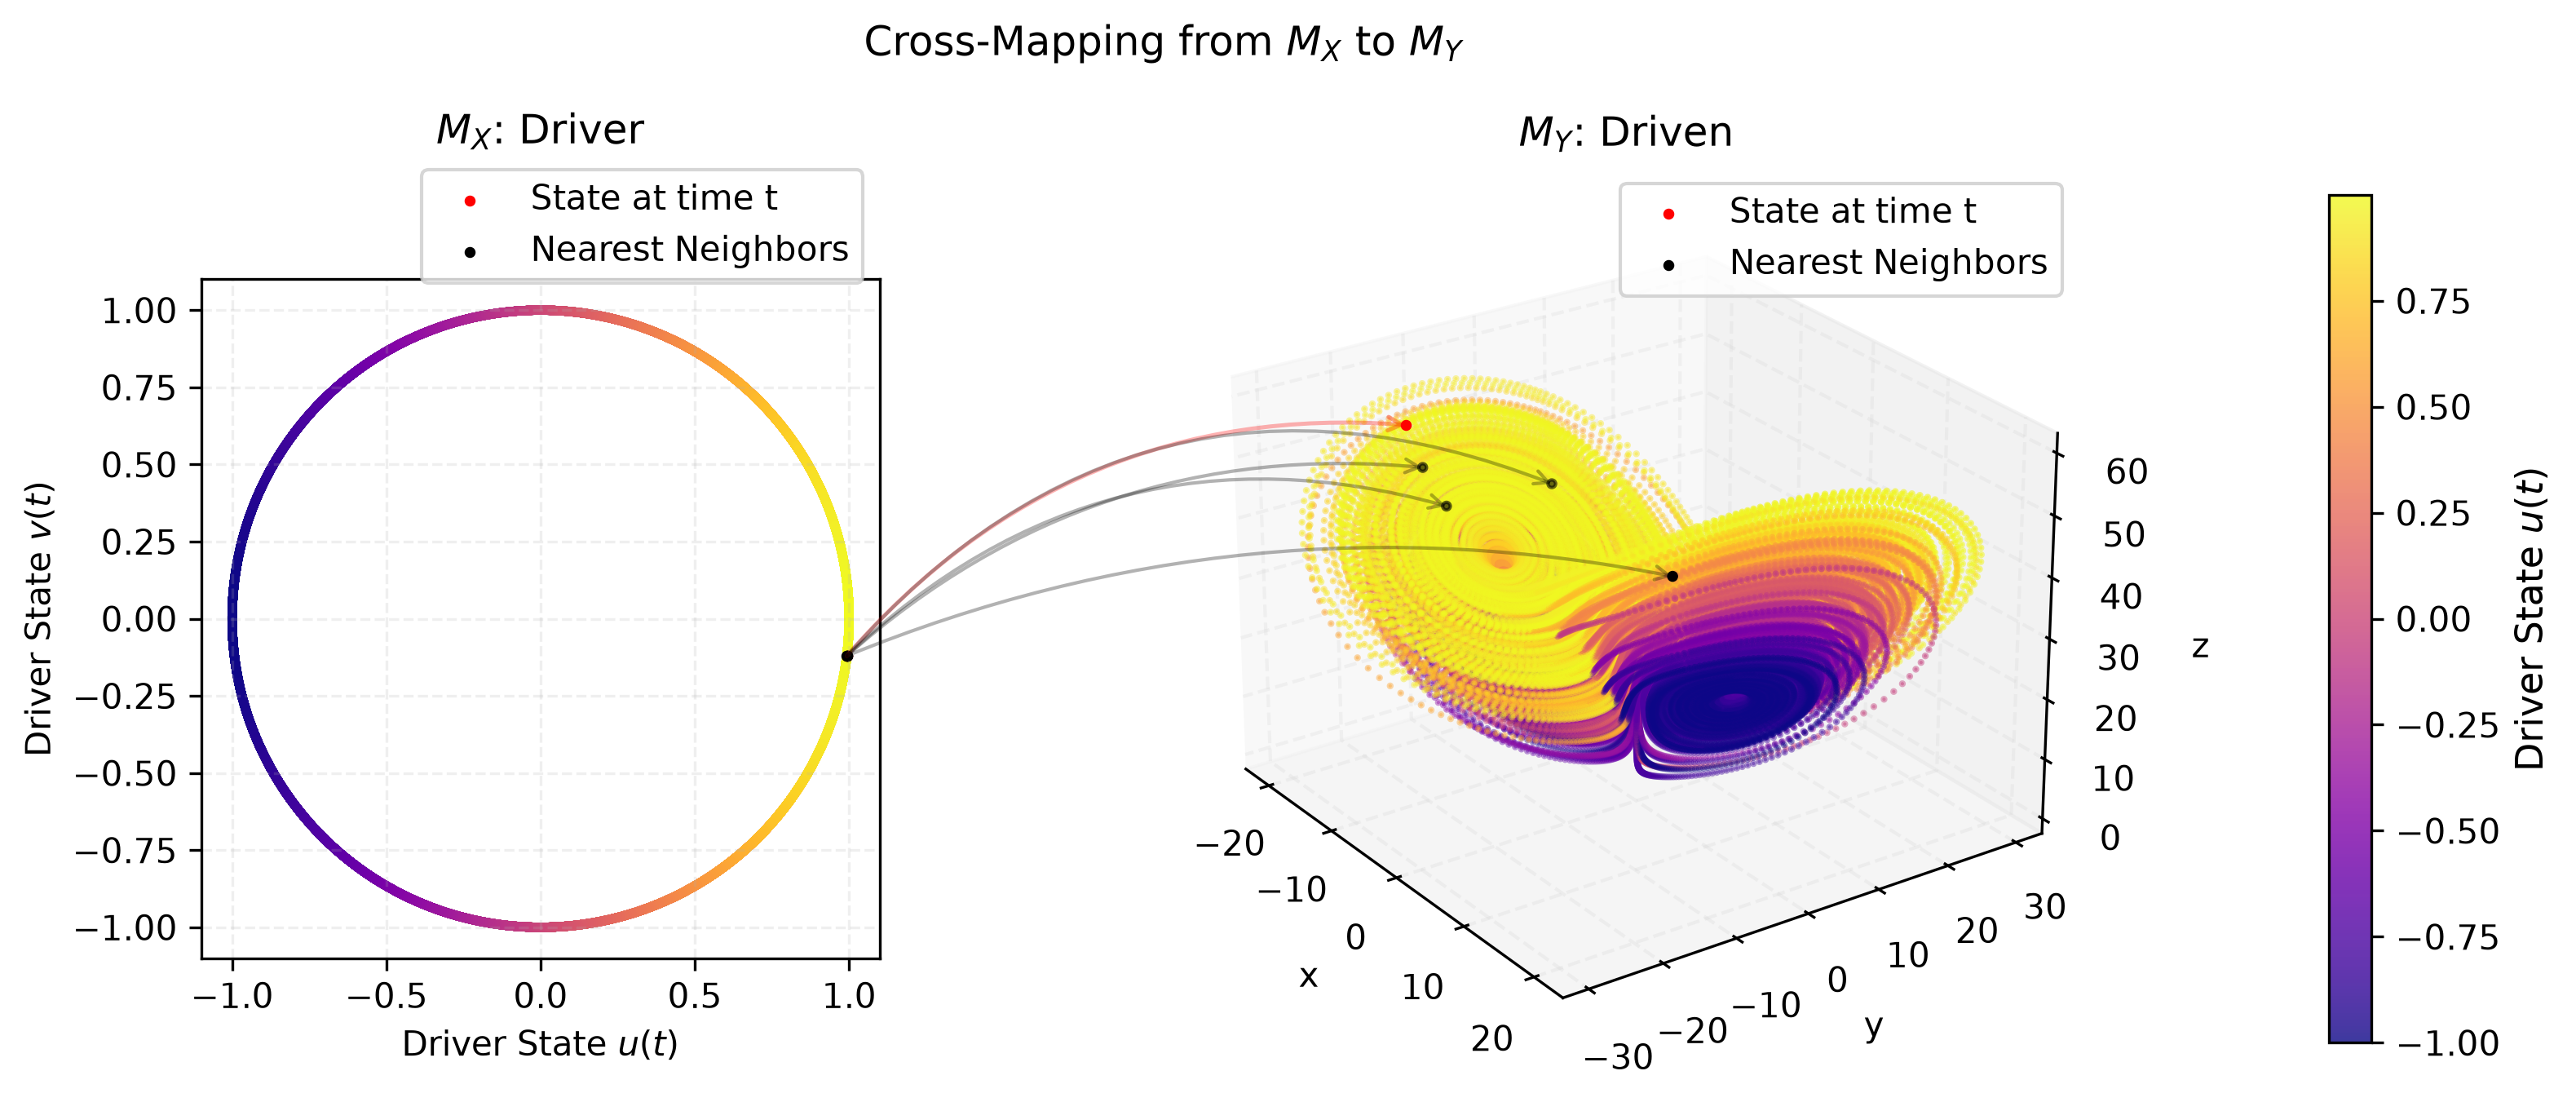

Saved figure to: /Users/deliacarpenter/Desktop/DRAFT14.2 Code/Figures/MY_xmap_MX.png


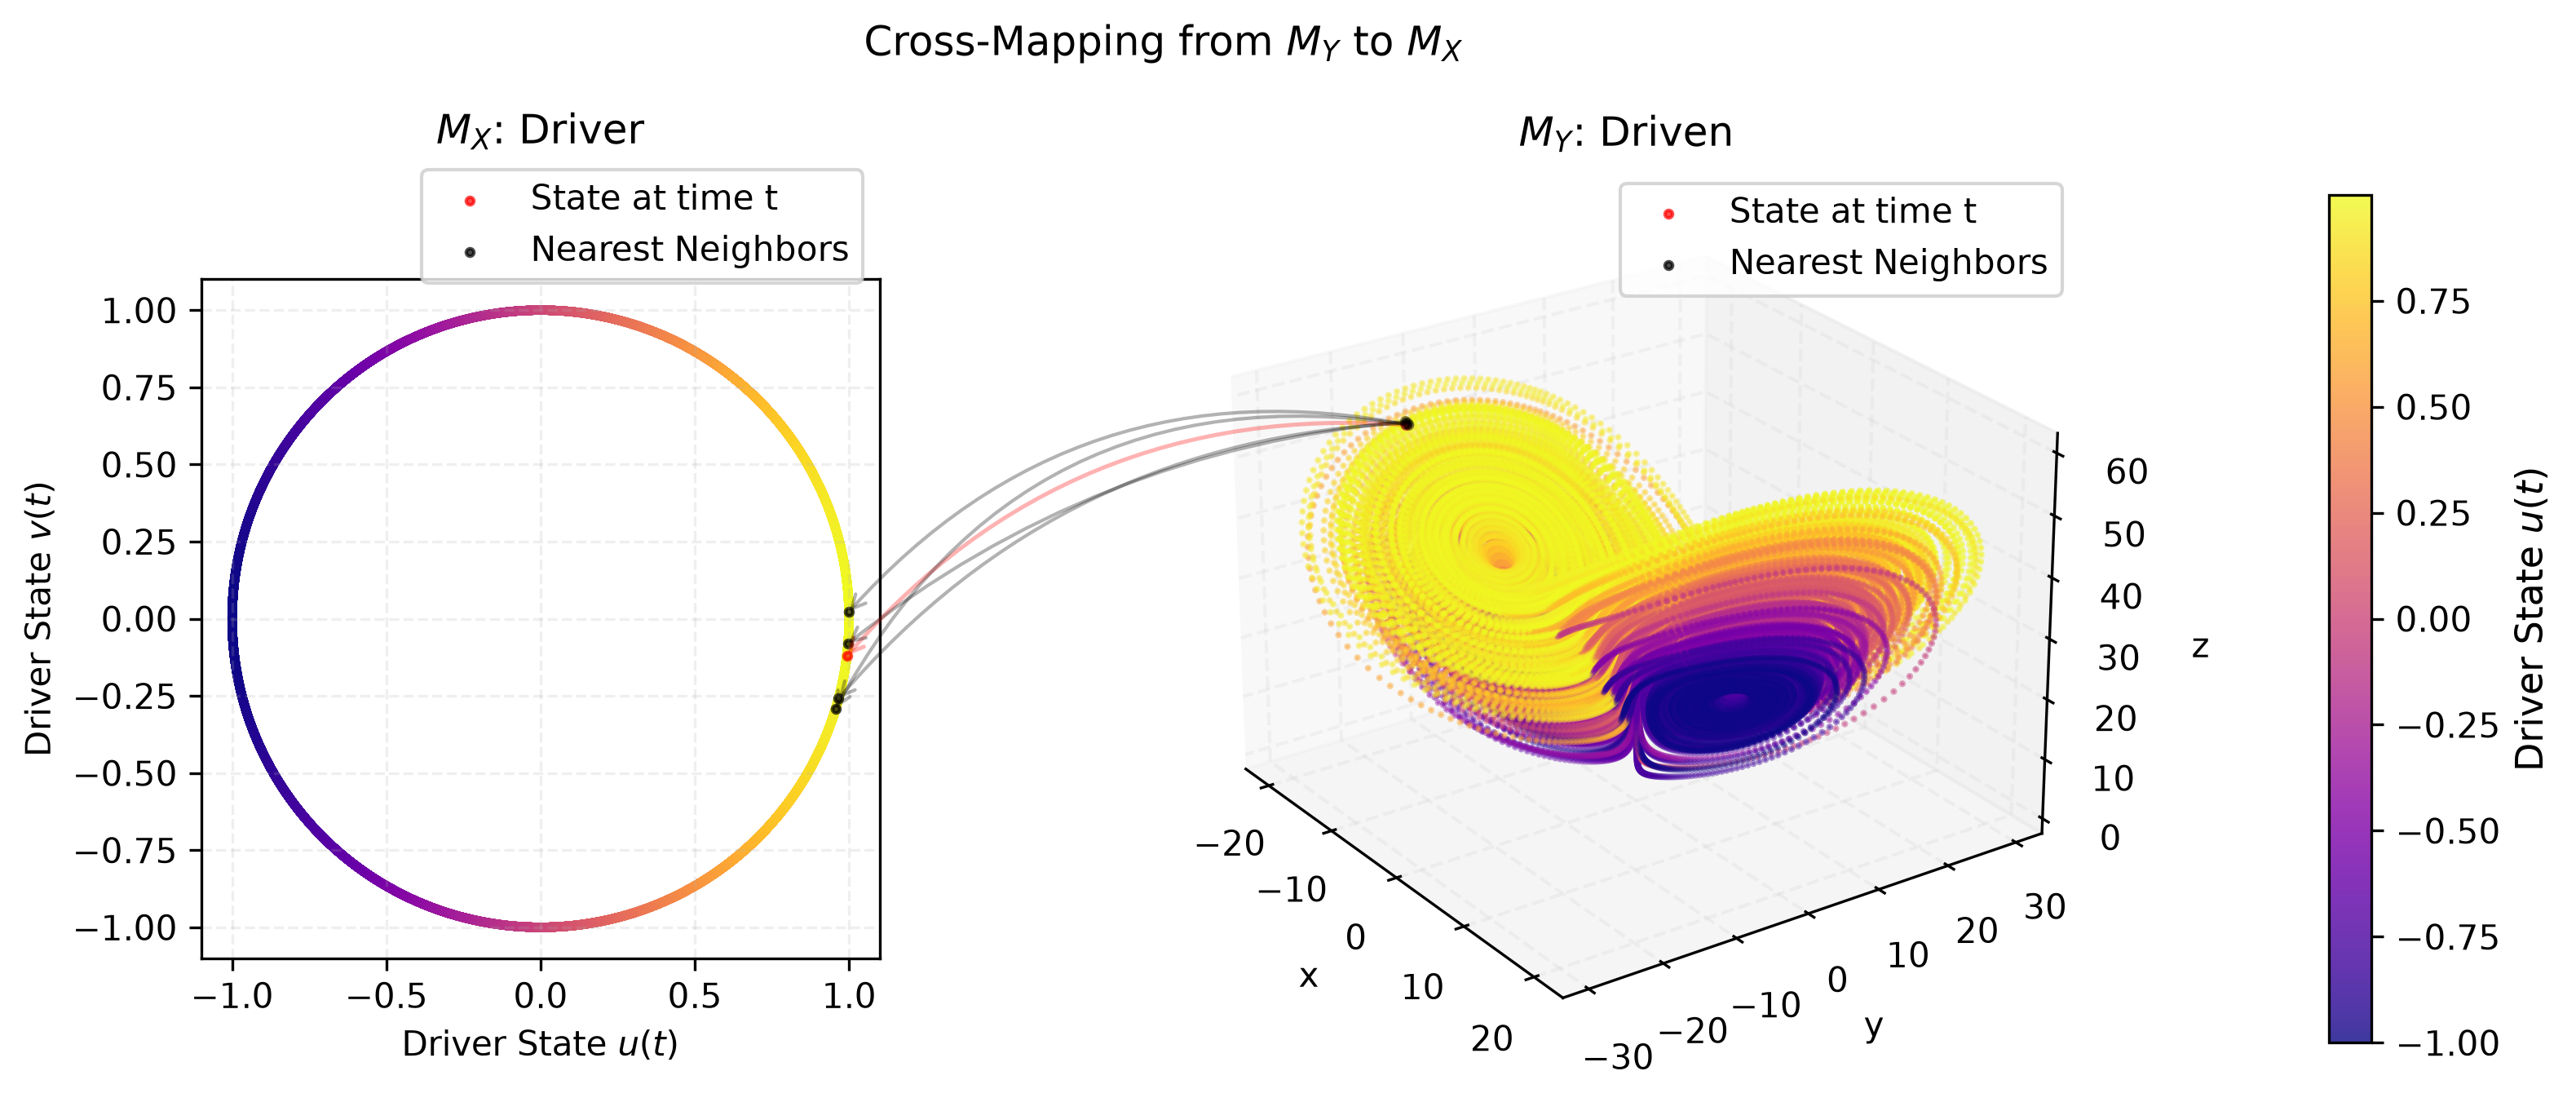

In [18]:
# 1. Load Data & Compute Nearest Neighbors
if make_plots:
    try:
        df = pd.read_csv(DATA_DIR / 'driven_lorenz_dataset.csv').iloc[::3].reset_index(drop=True)

        X_driver = df[["u_driver", "v_driver"]].values
        Y_lorenz = df[["x_lorenz", "y_lorenz", "z_lorenz"]].values

        query_idx, K, exclusion_radius = 6798, 4, 50 # Adjusted out of range index

        # Apply Theiler window mask
        valid_mask = np.ones(len(df), dtype=bool)
        valid_mask[max(0, query_idx - exclusion_radius): min(len(df), query_idx + exclusion_radius + 1)] = False
        valid_indices = np.where(valid_mask)[0]

        def get_nn(data):
            nn = NearestNeighbors(n_neighbors=K).fit(data[valid_mask])
            return valid_indices[nn.kneighbors(data[query_idx:query_idx + 1])[1][0]]

        indices_X, indices_Y = get_nn(X_driver), get_nn(Y_lorenz)

        # 2. Unified Plotting Function
        def plot_cross_mapping(direction="MX_to_MY", save_fig=True):
            is_mx_to_my = (direction == "MX_to_MY")
            target_nn = indices_X if is_mx_to_my else indices_Y
            arrow_style = "->" if is_mx_to_my else "<-"

            filename = "MX_xmap_MY.png" if is_mx_to_my else "MY_xmap_MX.png"
            title_dir = fr"$M_X$ to $M_Y$" if is_mx_to_my else fr"$M_Y$ to $M_X$"

            fig = plt.figure(figsize=(14, 6), dpi=300)

            # --- Panel A: Manifold M_X ---
            ax1 = fig.add_subplot(1, 2, 1)
            pos1 = ax1.get_position()
            scale = 0.75
            new_w, new_h = pos1.width * scale, pos1.height * scale
            ax1.set_position([
                pos1.x0 + (pos1.width - new_w) / 2,
                pos1.y0 + (pos1.height - new_h) / 2,
                new_w, new_h
            ])

            ax1.scatter(df["u_driver"], df["v_driver"], c=df["u_driver"], cmap="plasma", s=3, alpha=0.7)
            ax1.scatter(df.loc[query_idx, "u_driver"], df.loc[query_idx, "v_driver"], c="red", s=5, alpha=1 if is_mx_to_my else 0.7, label="State at time t")
            ax1.scatter(df.loc[target_nn, "u_driver"], df.loc[target_nn, "v_driver"], c="k", s=5, alpha=1 if is_mx_to_my else 0.7, label="Nearest Neighbors")

            ax1.set_title(r"$M_X$: Driver", pad=40)
            ax1.set_xlabel(r"Driver State $u(t)$")
            ax1.set_ylabel(r"Driver State $v(t)$")
            ax1.set_aspect("equal")
            ax1.grid(True, linestyle="--", alpha=0.2)
            ax1.legend(bbox_to_anchor=(0.3, 0.97))

            # --- Panel B: Manifold M_Y ---
            ax2 = fig.add_subplot(1, 2, 2, projection="3d")
            ax2.computed_zorder = False

            sc2 = ax2.scatter(df["x_lorenz"], df["y_lorenz"], df["z_lorenz"], c=df["u_driver"], cmap="plasma", s=1, alpha=0.8, zorder=1)
            ax2.scatter(df.loc[query_idx, "x_lorenz"], df.loc[query_idx, "y_lorenz"], df.loc[query_idx, "z_lorenz"], c="red", s=5, alpha=1 if is_mx_to_my else 0.7, zorder=2, label="State at time t")
            ax2.scatter(df.loc[target_nn, "x_lorenz"], df.loc[target_nn, "y_lorenz"], df.loc[target_nn, "z_lorenz"], c="k", s=5, alpha=1 if is_mx_to_my else 0.7, zorder=2, label="Nearest Neighbors")

            ax2.set_title(r"$M_Y$: Driven")
            ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("z")
            ax2.view_init(elev=25, azim=-35)
            for axis_name in ["xaxis", "yaxis", "zaxis"]:
                getattr(ax2, axis_name)._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})
            ax2.legend()

            # Colorbar & Title
            cbar = fig.colorbar(sc2, ax=[ax1, ax2], pad=0.1, shrink=0.75, location="right")
            cbar.set_label(r"Driver State $u(t)$", fontsize=11)
            plt.suptitle(f"Cross-Mapping from {title_dir}", x=0.45, y=0.9)

            # --- Connecting Lines ---
            fig.canvas.draw()

            def get_fig_coords_3d(x, y, z):
                p_2d = proj3d.proj_transform(x, y, z, ax2.get_proj())[:2]
                return fig.transFigure.inverted().transform(ax2.transData.transform(p_2d))

            # 1. Connect Query Point
            q_x, q_y, q_z = df.loc[query_idx, ["x_lorenz", "y_lorenz", "z_lorenz"]]
            fig.add_artist(ConnectionPatch(
                xyA=(df.loc[query_idx, "u_driver"], df.loc[query_idx, "v_driver"]), coordsA=ax1.transData,
                xyB=get_fig_coords_3d(q_x, q_y, q_z), coordsB=fig.transFigure,
                arrowstyle=arrow_style, color="red", linestyle="-", linewidth=1.2, mutation_scale=10, connectionstyle="arc3,rad=-0.25", alpha=0.3
            ))

            # 2. Connect Nearest Neighbors
            rads = np.linspace(-0.35, -0.15, len(target_nn))
            for idx, n_i in enumerate(target_nn):
                nx, ny, nz = df.loc[n_i, ["x_lorenz", "y_lorenz", "z_lorenz"]]
                fig.add_artist(ConnectionPatch(
                    xyA=(df.loc[n_i, "u_driver"], df.loc[n_i, "v_driver"]), coordsA=ax1.transData,
                    xyB=get_fig_coords_3d(nx, ny, nz), coordsB=fig.transFigure,
                    arrowstyle=arrow_style, color="black", linestyle="-", linewidth=1.0, alpha=0.3, mutation_scale=10, connectionstyle=f"arc3,rad={rads[idx]}"
                ))

            # --- Save Figure ---
            if save_fig:
                save_path = FIG_DIR / filename
                plt.savefig(save_path, bbox_inches='tight', dpi=300)
                print(f"Saved figure to: {save_path}")

            plt.show()

        # Generate Both Plots
        plot_cross_mapping("MX_to_MY")
        plot_cross_mapping("MY_to_MX")
    except Exception as e:
        print("Data files not found.")


### 2c. 5D Ecology System Figure

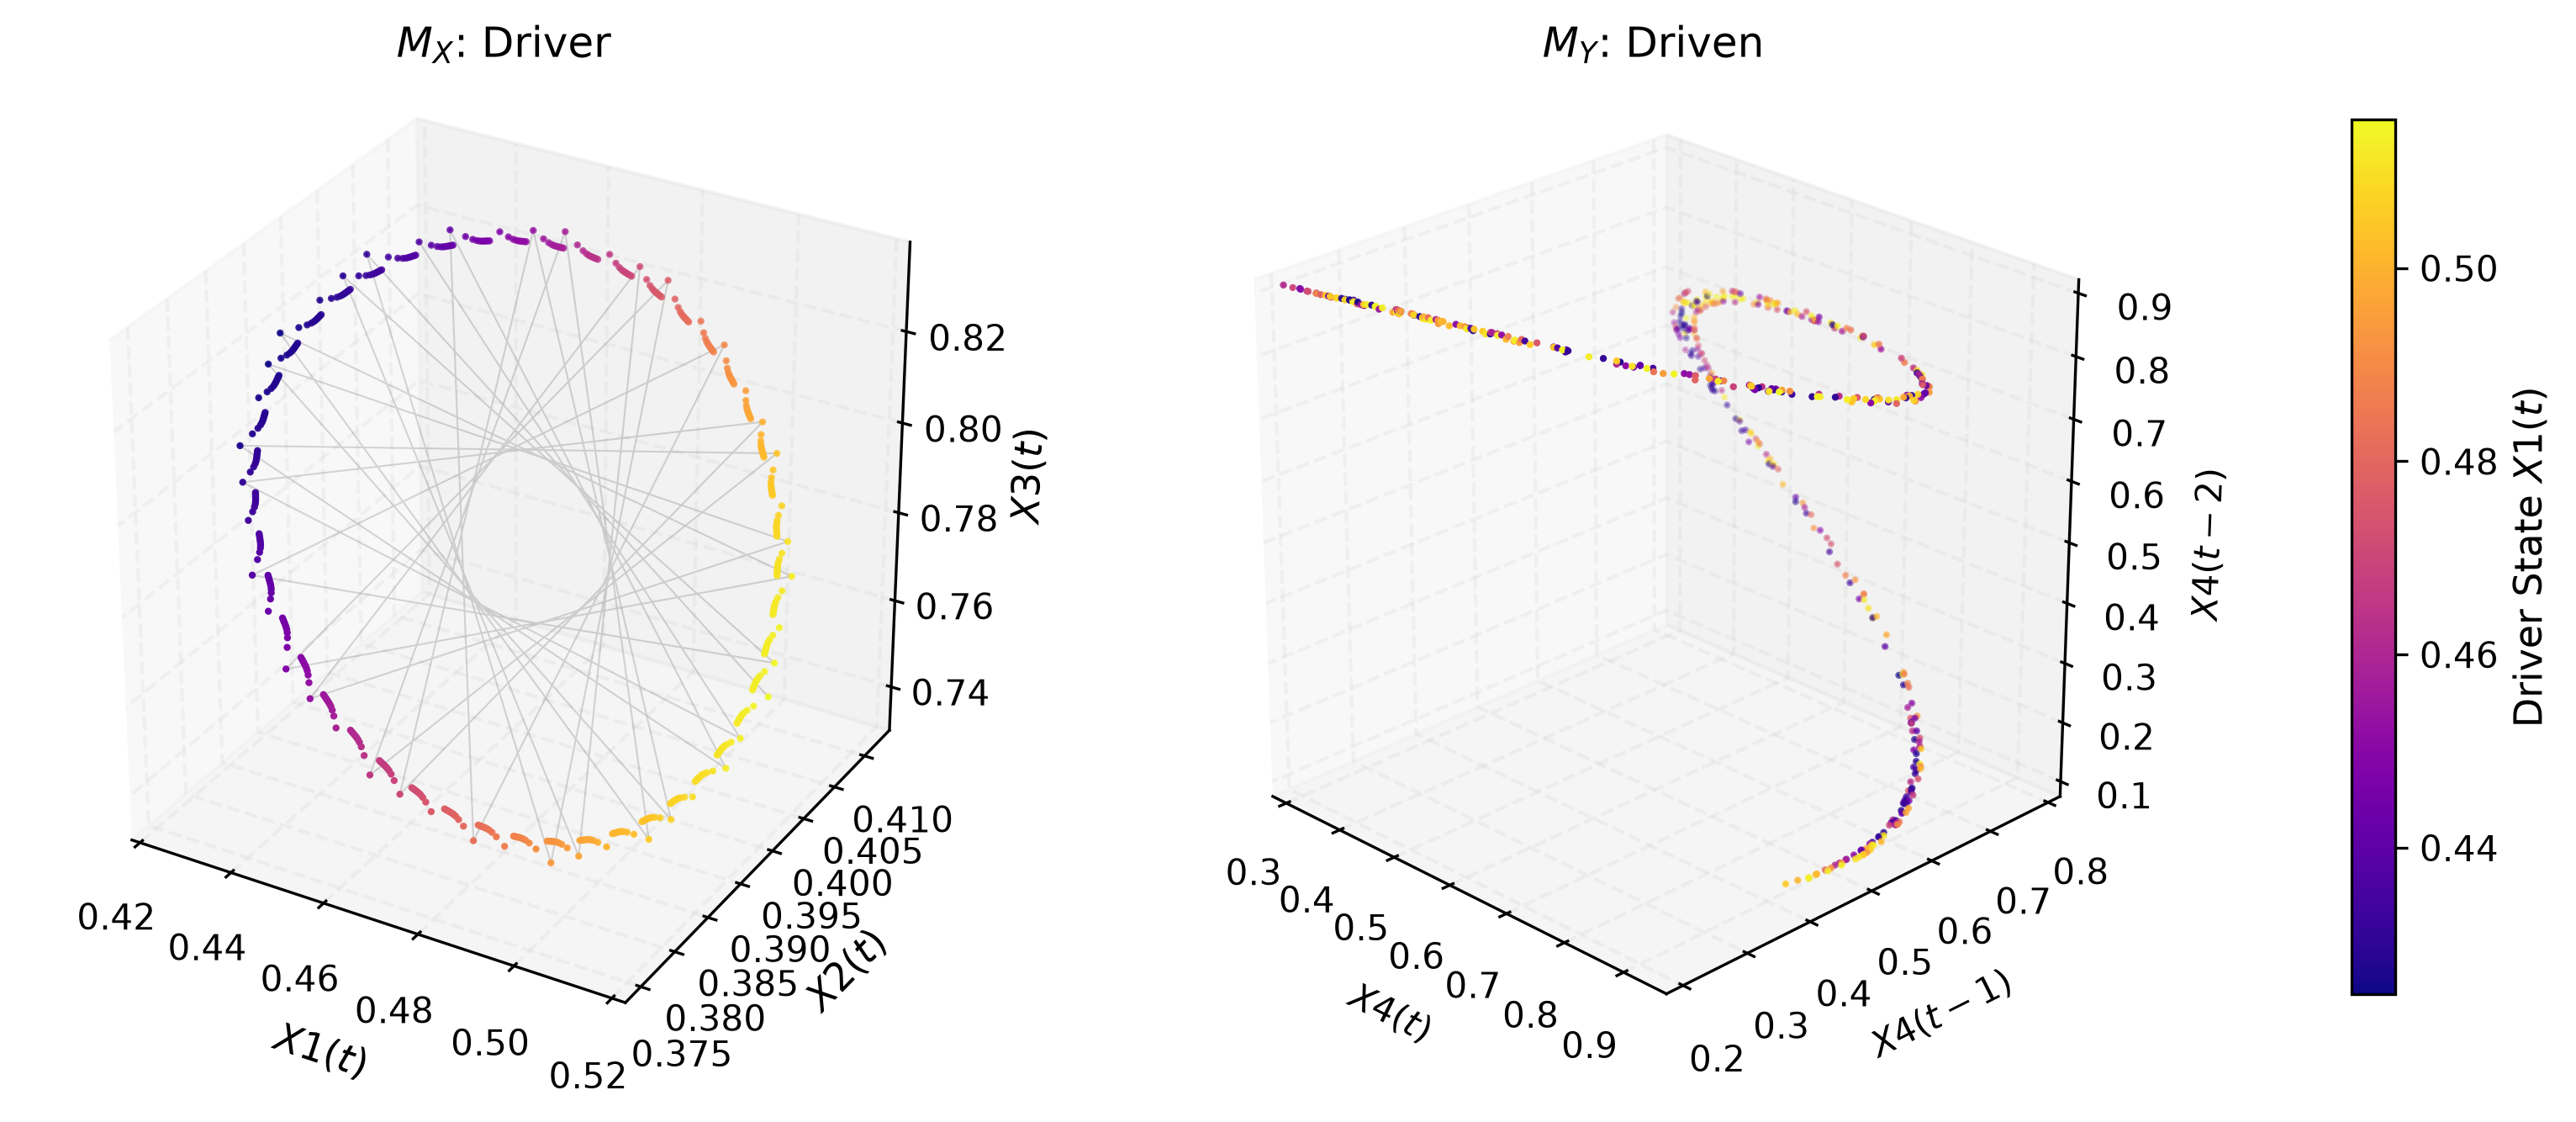

In [19]:
filename = "ecology_5D_reconstructions.png"
save_fig = False # Change to True to save figure

try:
    df = pd.read_csv(DATA_DIR / 'ecology5D.csv')

    driven = 'X4'
    slice_len = 30 

    tau = 1
    max_lag = 2 * tau

    x1 = df['X1'].values
    x2 = df['X2'].values
    x3 = df['X3'].values

    y1 = df[driven].iloc[max_lag:].values
    y2 = df[driven].iloc[tau : -tau].values
    y3 = df[driven].iloc[: -max_lag].values

    c_driver = df['X1'].iloc[max_lag:].values

    if make_plots:
        fig = plt.figure(figsize=(14, 6), dpi=300)

        # --- Panel A ---
        ax1 = fig.add_subplot(1, 2, 1, projection="3d")
        sc1 = ax1.scatter(x1, x2, x3, c=x1, cmap="plasma", s=1, alpha=1.0)
        ax1.plot(df.loc[:slice_len, 'X1'], df.loc[:slice_len, 'X2'], df.loc[:slice_len, 'X3'], alpha=0.15, linewidth=0.5, c='k')

        ax1.set_title(fr"$M_X$: Driver", fontsize=12)
        ax1.set_xlabel(r"$X1(t)$", fontsize=11)
        ax1.set_ylabel(r"$X2(t)$", fontsize=11)
        ax1.set_zlabel(r"$X3(t)$", fontsize=11)
        ax1.set_box_aspect((1, 1, 1))

        ax1.xaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})
        ax1.yaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})
        ax1.zaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})

        # --- Panel B ---
        ax2 = fig.add_subplot(1, 2, 2, projection="3d")
        sc2 = ax2.scatter(y1, y2, y3, c=c_driver, cmap="plasma", s=1, alpha=1)

        ax2.set_title(fr"$M_Y$: Driven", fontsize=12)
        ax2.set_xlabel(fr"${driven}(t)$", fontsize=10)
        ax2.set_ylabel(fr"${driven}(t-{tau})$", fontsize=10)
        ax2.set_zlabel(fr"${driven}(t-{2*tau})$", fontsize=10)
        ax2.set_box_aspect((1, 1, 1))

        pad_x = (y1.max() - y1.min()) * 0.05
        pad_y = (y2.max() - y2.min()) * 0.05
        pad_z = (y3.max() - y3.min()) * 0.05

        ax2.set_xlim(y1.min() - pad_x + 0.2, y1.max() + pad_x - 0.05)
        ax2.set_ylim(y2.min() - pad_y + 0.1, y2.max() + pad_y - 0.2)
        ax2.set_zlim(y3.min() - pad_z + 0.0, y3.max() + pad_z - 0.1)

        ax2.view_init(elev=25, azim=-45)

        ax2.xaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})
        ax2.yaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})
        ax2.zaxis._axinfo["grid"].update({"color": (0.8, 0.8, 0.8, 0.2), "linestyle": "--", "linewidth": 1})

        cbar = fig.colorbar(sc2, ax=[ax1, ax2], pad=0.08, shrink=0.75, location="right")
        cbar.set_label(fr"Driver State $X1(t)$", fontsize=11)

        if save_fig:
            save_path = FIG_DIR / filename
            plt.savefig(save_path, bbox_inches='tight', dpi=300)
            print(f"Saved figure to: {save_path}")

        plt.show()
except Exception as e:
    pass


## 3. Other Supplementary Analyses
### 3a. Table 1 Check

In [20]:
# 1. Define methods and raw data
methods = ['FPRM', 'Mean', 'k-NN', 'GPR', 'SVM', 'RF', 'NN', 'SVM*', 'NN*', 'MVCM', 'S-map', 'MetaTSI']

raw_data = {
    '120D Lorenz system': [
        ((0.89, 0.07), (0.41, 0.13)), ((0.01, 0.09), (1.11, 0.18)), ((0.64, 0.05), (0.82, 0.06)),
        ((0.71, 0.06), (0.57, 0.14)), ((0.70, 0.11), (0.69, 0.10)), ((0.51, 0.05), (0.82, 0.14)),
        ((0.74, 0.08), (0.65, 0.11)), ((0.81, 0.08), (0.53, 0.10)), ((0.82, 0.07), (0.49, 0.16)),
        ((0.63, 0.10), (0.67, 0.09)), ((0.27, 0.04), (1.13, 0.23)), ((0.72, 0.07), (0.68, 0.09))
    ],
    '120D Rossler system': [
        ((0.90, 0.14), (0.31, 0.21)), ((0.01, 0.04), (1.07, 0.15)), ((0.66, 0.07), (0.81, 0.12)),
        ((0.51, 0.08), (0.67, 0.11)), ((0.49, 0.08), (0.67, 0.09)), ((0.46, 0.06), (0.79, 0.11)),
        ((0.46, 0.05), (0.69, 0.18)), ((0.84, 0.07), (0.44, 0.09)), ((0.87, 0.10), (0.39, 0.22)),
        ((0.64, 0.12), (0.68, 0.08)), ((0.26, 0.05), (1.12, 0.17)), ((0.87, 0.09), (0.49, 0.14))
    ],
    '500D road occupancy rates': [
        ((0.83, 0.08), (0.49, 0.13)), ((0.01, 0.03), (1.01, 0.07)), ((0.61, 0.07), (0.86, 0.11)),
        ((0.67, 0.11), (0.68, 0.16)), ((0.64, 0.15), (0.69, 0.16)), ((0.53, 0.12), (0.89, 0.13)),
        ((0.68, 0.07), (0.87, 0.12)), ((0.77, 0.10), (0.65, 0.14)), ((0.70, 0.11), (0.76, 0.21)),
        ((0.60, 0.11), (0.66, 0.10)), ((0.25, 0.06), (1.22, 0.39)), ((0.75, 0.14), (0.66, 0.08))
    ],
    '64D EEG series': [
        ((0.95, 0.11), (0.27, 0.12)), ((0.01, 0.02), (1.07, 0.12)), ((0.06, 0.11), (1.36, 0.18)),
        ((0.66, 0.10), (0.71, 0.16)), ((0.62, 0.12), (0.75, 0.13)), ((0.68, 0.09), (0.85, 0.17)),
        ((0.64, 0.16), (0.85, 0.12)), ((0.91, 0.09), (0.38, 0.13)), ((0.89, 0.12), (0.39, 0.23)),
        ((0.58, 0.16), (0.71, 0.13)), ((0.22, 0.06), (1.32, 0.28)), ((0.12, 0.14), (1.01, 0.11))
    ],
    '52D exchange rates': [
        ((0.82, 0.14), (0.41, 0.24)), ((-0.01, 0.10), (1.03, 0.09)), ((0.71, 0.12), (0.68, 0.18)),
        ((0.79, 0.09), (0.43, 0.15)), ((0.79, 0.12), (0.52, 0.14)), ((0.65, 0.15), (0.77, 0.21)),
        ((0.78, 0.10), (0.46, 0.16)), ((0.76, 0.10), (0.48, 0.21)), ((0.78, 0.15), (0.51, 0.13)),
        ((0.51, 0.14), (0.79, 0.18)), ((0.24, 0.04), (1.30, 0.27)), ((0.86, 0.01), (0.31, 0.06))
    ]
}

records = []
for ds, vals in raw_data.items():
    for m, ((r, rs), (e, es)) in zip(methods, vals):
        records.append({
            'dataset': ds,
            'method': m,
            'rho_mean': r,
            'rho_sd': rs,
            'NRMSE_mean': e,
            'NRMSE_sd': es
        })

df = pd.DataFrame(records)

d = 0.005  # rounding tolerance
fav = (
    (df['NRMSE_mean'] + d)**2 +
    (df['NRMSE_sd'] + d)**2 +
    (df['rho_mean'].abs() + d)**2 +
    (df['rho_sd'] + d)**2
)

df['sum'] = fav.round(3)
df['valid'] = df['sum'] >= 1

# Save results
filename = 'table_1_validity_check.csv'
save_path = RESULTS_DIR / filename
df.to_csv(save_path)

print(f"Saved results to: {save_path}")


Saved results to: /Users/deliacarpenter/Desktop/DRAFT14.2 Code/Results/table_1_validity_check.csv


### 3b. Cross-correlations between coupled systems

In [21]:
def off_diag_mean(mat):
    mat = np.atleast_2d(mat)
    n = mat.shape[0]
    if n < 2:
        return np.nan 
    iu = np.triu_indices(n, k=1)
    return mat[iu].mean()

rows = []

try:
    for sys_name, cfg in SYSTEMS.items():
        df = cfg['df'].astype(float)
        cols = [str(c) for c in df.columns]
        
        x_cols = [c for c in cols if c.startswith('X')]
        y_cols = [c for c in cols if c.startswith('Y')]
        z_cols = [c for c in cols if c.startswith('Z')]
        
        # Case 1: Multiple subsystems in 3D
        if len(x_cols) > 1 and len(y_cols) > 1 and len(z_cols) > 1:
            corr_x = off_diag_mean(np.corrcoef(df[x_cols].to_numpy().T))
            corr_y = off_diag_mean(np.corrcoef(df[y_cols].to_numpy().T))
            corr_z = off_diag_mean(np.corrcoef(df[z_cols].to_numpy().T))
            
            avg_corr = np.nanmean([corr_x, corr_y, corr_z])
            n_subsystems = len(x_cols)

        # Case 2: Single 3D system
        elif len(x_cols) == 1 and len(y_cols) == 1 and len(z_cols) == 1:
            continue
        elif sys_name == 'ecology3D':
            continue

        # Case 3: 1-way system
        else:
            target_cols = x_cols if (len(y_cols) == 0 and len(z_cols) == 0) else cols
            corr_x = off_diag_mean(np.corrcoef(df[target_cols].to_numpy().T))
            corr_y = corr_z = np.nan
            
            avg_corr = corr_x
            n_subsystems = len(target_cols)

        rows.append({
            'System': sys_name,
            'Variables': n_subsystems,
            'Corr_X': corr_x,
            'Corr_Y': corr_y,
            'Corr_Z': corr_z,
            'Avg_Cross_Corr': avg_corr,
        })

    results_table = pd.DataFrame(rows)
    display(results_table)

    # Save results
    filename = 'avg_cross_correlations.csv'
    save_path = RESULTS_DIR / filename
    results_table.to_csv(save_path)
    
    print(f"Saved results to: {save_path}")
    
except Exception:
    pass


,System,Variables,Corr_X,Corr_Y,Corr_Z,Avg_Cross_Corr
0,lorenz120D,40,0.629870,0.407004,0.456338,0.497737
1,rossler120D,40,0.999502,0.999368,0.999476,0.999448
2,road,500,0.603136,NaN,NaN,0.603136
3,eeg,64,0.866330,NaN,NaN,0.866330
4,exchange,52,0.602655,NaN,NaN,0.602655
5,wind,231,0.653100,NaN,NaN,0.653100


Saved results to: /Users/deliacarpenter/Desktop/DRAFT14.2 Code/Results/avg_cross_correlations.csv
